# ADP 20회 - 날씨 회귀 상세 후기 보충

출처: adp_20_summary.pdf pp.1~4: temps.csv RF·SVM·예측 기준선

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'20회/보충';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 날씨 예측

자료: temps.csv

348개 합성 일별 관측. average=미리 알려진 전년도 기준선으로 가정. friend는 예측 시점 가용성 불명확하여 제외. 미래 예측이므로 시간순 7:3.

### 1-1

EDA·요일 원핫 전처리와 시간순 분할을 설명하고 전년도 평균 기준선 MAE를 구하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** 후기는 랜덤 분할을 제안하지만 미래 날씨 예측에서는 시간순 평가로 보완합니다. 평균 기준선은 학습 y 평균과 전년도 average를 구분합니다.

          year       month         day  ...      actual     average      friend
count    348.0  348.000000  348.000000  ...  348.000000  348.000000  348.000000
unique     NaN         NaN         NaN  ...         NaN         NaN         NaN
top        NaN         NaN         NaN  ...         NaN         NaN         NaN
freq       NaN         NaN         NaN  ...         NaN         NaN         NaN
mean    2016.0    6.293103   15.482759  ...   14.986603   15.083650   14.815325
std        0.0    3.309276    8.769363  ...    7.650625    7.249496    8.075888
min     2016.0    1.000000    1.000000  ...    0.179031    5.000368   -1.904113
25%     2016.0    3.000000    8.000000  ...    7.789826    7.661146    7.655865
50%     2016.0    6.000000   15.000000  ...   15.350272   15.771726   14.888815
75%     2016.0    9.000000   23.000000  ...   21.979194   22.338854   21.510495
max     2016.0   12.000000   31.000000  ...   28.083004   24.999632   33.367533

[11 rows x 10 columns]
year       0
mon

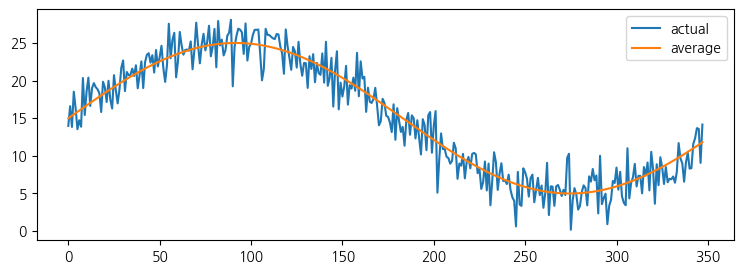

In [2]:
weather=load('temps.csv');print(weather.describe(include='all'));print(weather.isna().sum())
features=['month','day','week','temp_1','temp_2','average'];X=weather[features];y=weather.actual
cut=int(len(y)*.7);train=np.arange(cut);test=np.arange(cut,len(y))
print('baseline test MAE:',np.mean(np.abs(y.iloc[test]-weather.average.iloc[test])))
weather.plot(y=['actual','average'],figsize=(9,3));plt.show()

### 1-2

RF와 SVR를 train TimeSeriesSplit RMSE로 비교하고 변수 중요도를 분석하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** RBF SVR는 coef_가 없어 공통 permutation importance를 사용합니다. 여기 중요도는 학습 자료의 설명이며 일반화 중요도가 아닙니다.

  model   CV_RMSE
0    rf  3.690184
1   svr  5.858439


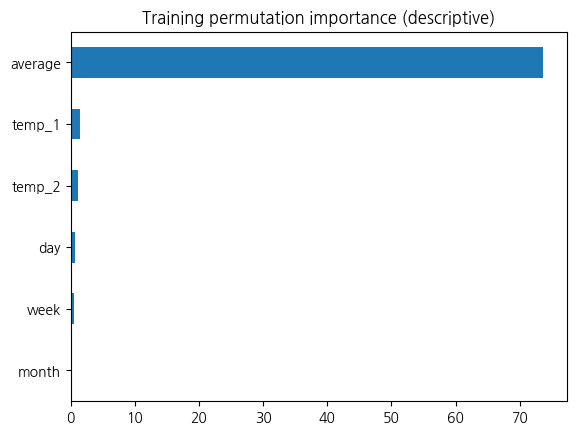

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit,cross_val_score
from sklearn.inspection import permutation_importance
models={};rows=[]
for name,est in [('rf',RandomForestRegressor(n_estimators=60,random_state=1234)),('svr',SVR())]:
    pipe=tabular_pipeline(X,est);scores=cross_val_score(pipe,X.iloc[train],y.iloc[train],cv=TimeSeriesSplit(3),scoring='neg_mean_squared_error')
    rows.append({'model':name,'CV_RMSE':np.sqrt(-scores).mean()});models[name]=pipe
ranking=pd.DataFrame(rows);print(ranking);winner=ranking.loc[ranking.CV_RMSE.idxmin(),'model'];final=models[winner].fit(X.iloc[train],y.iloc[train])
importance=permutation_importance(final,X.iloc[train],y.iloc[train],n_repeats=5,random_state=1234,scoring='neg_mean_squared_error')
pd.Series(importance.importances_mean,index=features).sort_values().plot.barh();plt.title('Training permutation importance (descriptive)');plt.show()

### 1-3

선정 모델의 보류 RMSE·MAE·R²를 기준선과 비교하고 운영상 한계를 서술하시오.

**출처/보완:** 주제는 첨부 자료, 세부 조건·수치는 복원 연습용 보완

**풀이 근거:** test로 최종 모델을 고르지 않습니다. lag 입력은 매일 과거 실제값이 새로 관측되는 one-step 운영 가정입니다.

In [4]:
pred=final.predict(X.iloc[test]);print(winner,{'RMSE':np.sqrt(mean_squared_error(y.iloc[test],pred)),'MAE':np.mean(np.abs(y.iloc[test]-pred)),'R2':r2_score(y.iloc[test],pred)})
pd.DataFrame({'row_id':test,'actual':y.iloc[test].to_numpy(),'prediction':pred,'baseline':weather.average.iloc[test].to_numpy()}).to_csv(OUT/'weather_predictions.csv',index=False)
print('합성 자료의 튜닝 우위는 실제 데이터 성능 근거가 아님. lag는 예측 시점 관측 가능성을 점검. MAPE는 실제값 분모, 섭씨 0 부근에서는 불안정.')

rf {'RMSE': np.float64(2.7297437473686963), 'MAE': np.float64(2.3047204680436475), 'R2': -0.004117205624019071}
합성 자료의 튜닝 우위는 실제 데이터 성능 근거가 아님. lag는 예측 시점 관측 가능성을 점검. MAPE는 실제값 분모, 섭씨 0 부근에서는 불안정.
